In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

path = kagglehub.dataset_download("arashnic/cinema-ticket")

print("Path to dataset files:", path)
print("Files in directory:", os.listdir(path))

csv_path = os.path.join(path, "cinemaTicket_Ref.csv")
ds = pd.read_csv(csv_path)

print(ds.head())

Using Colab cache for faster access to the 'cinema-ticket' dataset.
Path to dataset files: /kaggle/input/cinema-ticket
Files in directory: ['cinemaTicket_Ref.csv']
   film_code  cinema_code  total_sales  tickets_sold  tickets_out  show_time  \
0       1492          304      3900000            26            0          4   
1       1492          352      3360000            42            0          5   
2       1492          489      2560000            32            0          4   
3       1492          429      1200000            12            0          1   
4       1492          524      1200000            15            0          3   

   occu_perc  ticket_price  ticket_use    capacity        date  month  \
0       4.26      150000.0          26  610.328638  2018-05-05      5   
1       8.08       80000.0          42  519.801980  2018-05-05      5   
2      20.00       80000.0          32  160.000000  2018-05-05      5   
3      11.01      100000.0          12  108.991826  2018-05-05 

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import warnings

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
print("Setup complete.")

Setup complete.


In [9]:
!pip install -q kagglehub xgboost

In [10]:
print("Dataset Shape:", ds.shape)

print("\nColumn Names:")
print(ds.columns.tolist())

print("\nData Types:")
print(ds.dtypes)

print("\nMissing Values:")
print(ds.isnull().sum())

print("\nDuplicate Records:", ds.duplicated().sum())

display(ds.describe().T)

Dataset Shape: (142524, 14)

Column Names:
['film_code', 'cinema_code', 'total_sales', 'tickets_sold', 'tickets_out', 'show_time', 'occu_perc', 'ticket_price', 'ticket_use', 'capacity', 'date', 'month', 'quarter', 'day']

Data Types:
film_code         int64
cinema_code       int64
total_sales       int64
tickets_sold      int64
tickets_out       int64
show_time         int64
occu_perc       float64
ticket_price    float64
ticket_use        int64
capacity        float64
date             object
month             int64
quarter           int64
day               int64
dtype: object

Missing Values:
film_code         0
cinema_code       0
total_sales       0
tickets_sold      0
tickets_out       0
show_time         0
occu_perc       125
ticket_price      0
ticket_use        0
capacity        125
date              0
month             0
quarter           0
day               0
dtype: int64

Duplicate Records: 106


,count,mean,std,min,25%,50%,75%,max
film_code,142524.0,1.518985e+03,3.618445e+01,1471.000000,1.485000e+03,1.498000e+03,1.556000e+03,1.589000e+03
cinema_code,142524.0,3.203784e+02,1.597012e+02,32.000000,1.810000e+02,3.240000e+02,4.740000e+02,6.370000e+02
total_sales,142524.0,1.234728e+07,3.065486e+07,20000.000000,1.260000e+06,3.720000e+06,1.110000e+07,1.262820e+09
tickets_sold,142524.0,1.401376e+02,2.797587e+02,1.000000,1.800000e+01,5.000000e+01,1.430000e+02,8.499000e+03
tickets_out,142524.0,2.374126e-01,2.923206e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,3.110000e+02
show_time,142524.0,3.932103e+00,3.056276e+00,1.000000,2.000000e+00,3.000000e+00,5.000000e+00,6.000000e+01
occu_perc,142399.0,1.996599e+01,2.265345e+01,0.000000,3.750000e+00,1.035000e+01,2.821000e+01,1.475000e+02
ticket_price,142524.0,8.123460e+04,3.323660e+04,483.870968,6.000000e+04,7.945424e+04,1.000000e+05,7.000000e+05
ticket_use,142524.0,1.399002e+02,2.795649e+02,-219.000000,1.800000e+01,5.000000e+01,1.430000e+02,8.499000e+03
capacity,142399.0,8.547236e+02,9.531181e+02,-2.000000,2.769945e+02,5.257143e+02,1.038961e+03,9.692097e+03


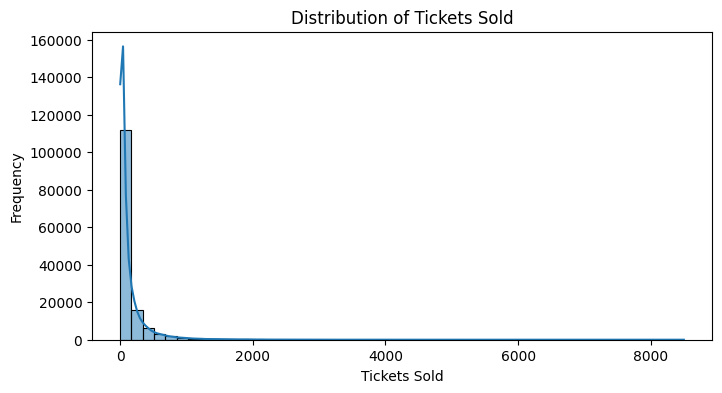

In [11]:
plt.figure(figsize=(8, 4))

sns.histplot(ds["tickets_sold"], bins=50, kde=True)

plt.title("Distribution of Tickets Sold")
plt.xlabel("Tickets Sold")
plt.ylabel("Frequency")

plt.show()

In [12]:
print("Minimum tickets sold:", ds["tickets_sold"].min())
print("Maximum tickets sold:", ds["tickets_sold"].max())
print("Average tickets sold:", ds["tickets_sold"].mean())
print("Median tickets sold:", ds["tickets_sold"].median())

Minimum tickets sold: 1
Maximum tickets sold: 8499
Average tickets sold: 140.13756981280346
Median tickets sold: 50.0


In [13]:
# Convert date column into datetime format
ds["date"] = pd.to_datetime(ds["date"], errors="coerce")

# Check date range
print("Start Date:", ds["date"].min())
print("End Date:", ds["date"].max())

# Check invalid dates
print("Invalid Dates:", ds["date"].isna().sum())

# Display sample records
display(ds[["date", "tickets_sold", "capacity"]].head())

Start Date: 2018-02-21 00:00:00
End Date: 2018-11-04 00:00:00
Invalid Dates: 0


,date,tickets_sold,capacity
0,2018-05-05,26,610.328638
1,2018-05-05,42,519.801980
2,2018-05-05,32,160.000000
3,2018-05-05,12,108.991826
4,2018-05-05,15,89.982004


In [14]:
print("Negative ticket sales:", (ds["tickets_sold"] < 0).sum())
print("Zero capacity records:", (ds["capacity"] <= 0).sum())

print("\nTicket Sales Summary:")
print(ds["tickets_sold"].describe())

print("\nCapacity Summary:")
print(ds["capacity"].describe())

Negative ticket sales: 0
Zero capacity records: 54

Ticket Sales Summary:
count    142524.000000
mean        140.137570
std         279.758733
min           1.000000
25%          18.000000
50%          50.000000
75%         143.000000
max        8499.000000
Name: tickets_sold, dtype: float64

Capacity Summary:
count    142399.000000
mean        854.723605
std         953.118103
min          -2.000000
25%         276.994486
50%         525.714286
75%        1038.961039
max        9692.097160
Name: capacity, dtype: float64


In [15]:
ds["day_of_week"] = ds["date"].dt.dayofweek
ds["day_of_month"] = ds["date"].dt.day
ds["month"] = ds["date"].dt.month
ds["quarter"] = ds["date"].dt.quarter
ds["is_weekend"] = (ds["day_of_week"] >= 5).astype(int)

display(ds[["date", "day_of_week", "month",
            "quarter", "is_weekend"]].head())

,date,day_of_week,month,quarter,is_weekend
0,2018-05-05,5,5,2,1
1,2018-05-05,5,5,2,1
2,2018-05-05,5,5,2,1
3,2018-05-05,5,5,2,1
4,2018-05-05,5,5,2,1


In [16]:
# Remove records with invalid dates
ds = ds.dropna(subset=["date"])

# Remove records with invalid ticket sales or capacity
ds = ds[
    (ds["tickets_sold"] >= 0) &
    (ds["capacity"] > 0)
].copy()

# Remove exact duplicate records
ds = ds.drop_duplicates()

ds = ds.sort_values("date").reset_index(drop=True)

print("Dataset shape after cleaning:", ds.shape)
print("Missing values:\n", ds.isnull().sum())

Dataset shape after cleaning: (142241, 17)
Missing values:
 film_code       0
cinema_code     0
total_sales     0
tickets_sold    0
tickets_out     0
show_time       0
occu_perc       0
ticket_price    0
ticket_use      0
capacity        0
date            0
month           0
quarter         0
day             0
day_of_week     0
day_of_month    0
is_weekend      0
dtype: int64


In [17]:
# Calculate occupancy percentage for analysis
ds["calculated_occupancy"] = (
    ds["tickets_sold"] / ds["capacity"]
) * 100

print("Average Occupancy:", round(ds["calculated_occupancy"].mean(), 2), "%")
print("Minimum Occupancy:", round(ds["calculated_occupancy"].min(), 2), "%")
print("Maximum Occupancy:", round(ds["calculated_occupancy"].max(), 2), "%")

display(ds[[
    "tickets_sold",
    "capacity",
    "calculated_occupancy"
]].head())

Average Occupancy: 19.96 %
Minimum Occupancy: 0.03 %
Maximum Occupancy: 147.5 %


,tickets_sold,capacity,calculated_occupancy
0,267,559.045226,47.76
1,3,144.927536,2.07
2,2,256.410256,0.78
3,74,3957.219251,1.87
4,73,1210.613599,6.03


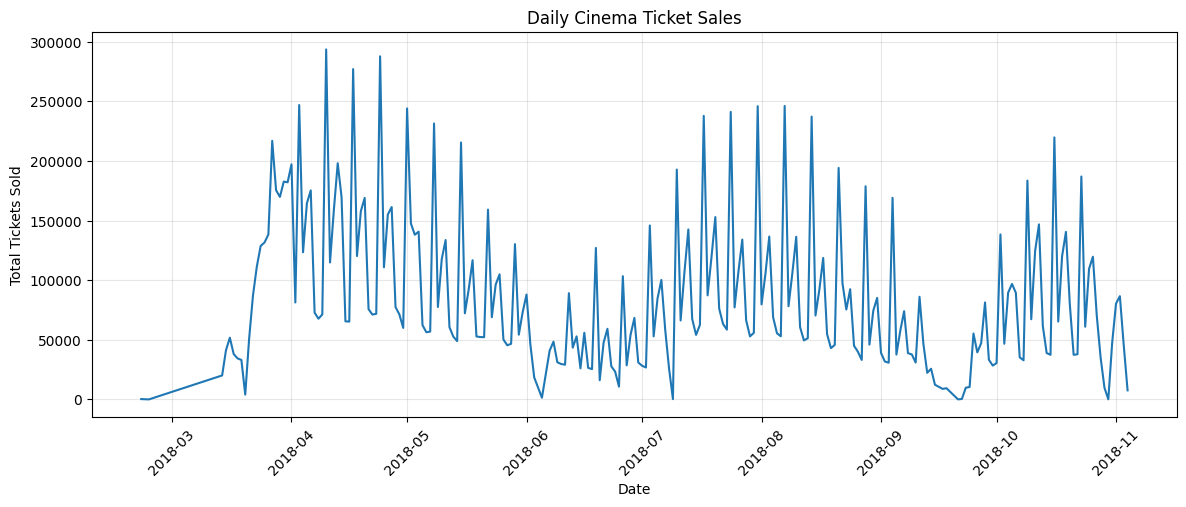

In [18]:
daily_sales = ds.groupby("date")["tickets_sold"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)

plt.title("Daily Cinema Ticket Sales")
plt.xlabel("Date")
plt.ylabel("Total Tickets Sold")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

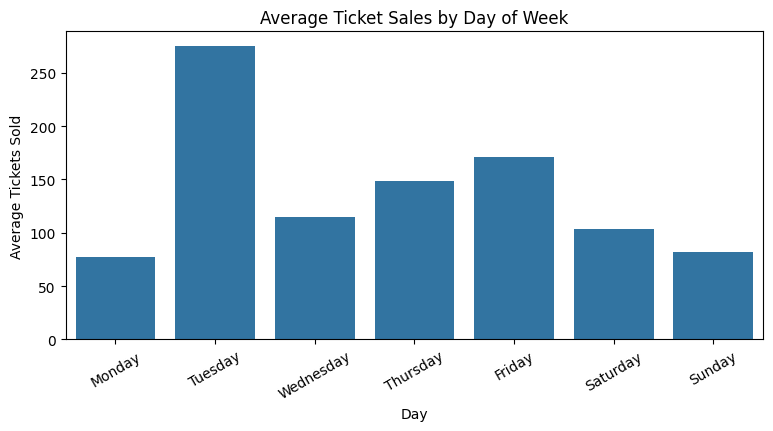

,tickets_sold
Monday,76.900809
Tuesday,275.130905
Wednesday,114.727168
Thursday,148.339744
Friday,171.445375
Saturday,103.218105
Sunday,81.464432


In [19]:
weekday_sales = ds.groupby("day_of_week")["tickets_sold"].mean()

weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales.index = weekday_names

plt.figure(figsize=(9, 4))
sns.barplot(x=weekday_sales.index, y=weekday_sales.values)

plt.title("Average Ticket Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Tickets Sold")
plt.xticks(rotation=30)
plt.show()

display(weekday_sales)

In [20]:
# Define target
target = "tickets_sold"

# Features available before the show
features = [
    "film_code",
    "cinema_code",
    "show_time",
    "capacity",
    "ticket_price",
    "day_of_week",
    "day_of_month",
    "month",
    "quarter",
    "is_weekend"
]

# Keep only required columns
model_data = ds[["date"] + features + [target]].copy()

print("Model dataset shape:", model_data.shape)
display(model_data.head())

Model dataset shape: (142241, 12)


,date,film_code,cinema_code,show_time,capacity,ticket_price,day_of_week,day_of_month,month,quarter,is_weekend,tickets_sold
0,2018-02-21,1471,448,2,559.045226,119962.546816,2,21,2,1,0,267
1,2018-02-23,1471,518,1,144.927536,60000.000000,4,23,2,1,0,3
2,2018-03-14,1481,522,3,256.410256,120000.000000,2,14,3,1,0,2
3,2018-03-14,1485,52,7,3957.219251,95270.270270,2,14,3,1,0,74
4,2018-03-14,1485,72,14,1210.613599,94520.547945,2,14,3,1,0,73


In [21]:
print("Missing values before cleaning:")
print(model_data.isnull().sum())

# Remove rows where target or essential capacity is missing
model_data = model_data.dropna(
    subset=["tickets_sold", "capacity", "date"]
)

# Sort chronologically
model_data = model_data.sort_values("date").reset_index(drop=True)

print("\nDataset shape after cleaning:", model_data.shape)
print("Missing target values:", model_data[target].isnull().sum())

Missing values before cleaning:
date            0
film_code       0
cinema_code     0
show_time       0
capacity        0
ticket_price    0
day_of_week     0
day_of_month    0
month           0
quarter         0
is_weekend      0
tickets_sold    0
dtype: int64

Dataset shape after cleaning: (142241, 12)
Missing target values: 0


In [22]:
# Get unique dates in chronological order
unique_dates = sorted(model_data["date"].unique())

train_end = int(len(unique_dates) * 0.70)
val_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

train_df = model_data[model_data["date"].isin(train_dates)].copy()
val_df = model_data[model_data["date"].isin(val_dates)].copy()
test_df = model_data[model_data["date"].isin(test_dates)].copy()

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nTraining period:", train_df["date"].min(), "to", train_df["date"].max())
print("Validation period:", val_df["date"].min(), "to", val_df["date"].max())
print("Testing period:", test_df["date"].min(), "to", test_df["date"].max())

Training records: 100201
Validation records: 19353
Testing records: 22687

Training period: 2018-02-21 00:00:00 to 2018-08-23 00:00:00
Validation period: 2018-08-24 00:00:00 to 2018-09-29 00:00:00
Testing period: 2018-09-30 00:00:00 to 2018-11-04 00:00:00


In [23]:
X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (100201, 10)
X_val: (19353, 10)
X_test: (22687, 10)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = [
    "film_code",
    "cinema_code",
    "show_time"
]

numerical_features = [
    "capacity",
    "ticket_price",
    "day_of_week",
    "day_of_month",
    "month",
    "quarter",
    "is_weekend"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [25]:
# Calculate historical occupancy using training data only
train_occupancy = (
    train_df["tickets_sold"] / train_df["capacity"]
)

baseline_data = train_df.copy()
baseline_data["historical_occupancy"] = train_occupancy

# Average occupancy for each combination
occupancy_lookup = baseline_data.groupby(
    ["film_code", "cinema_code", "show_time"]
)["historical_occupancy"].mean()

# Overall training occupancy for unseen combinations
overall_occupancy = train_occupancy.mean()

def predict_baseline(data):
    keys = pd.MultiIndex.from_frame(
        data[["film_code", "cinema_code", "show_time"]]
    )

    historical_occupancy = occupancy_lookup.reindex(keys)

    historical_occupancy = historical_occupancy.fillna(
        overall_occupancy
    )

    predictions = historical_occupancy.values * data["capacity"].values

    return np.clip(predictions, 0, data["capacity"].values)

baseline_predictions = predict_baseline(val_df)

print("Baseline predictions:", baseline_predictions[:10])

Baseline predictions: [ 103.73655019   56.98320071 4237.17719967 1993.34519715 1678.10712583
  307.12387981 1464.36831381  972.64221542   20.48499117   28.5       ]


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_model(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    wape = (
        np.sum(np.abs(actual - predicted)) /
        np.sum(np.abs(actual))
    ) * 100

    print(f"\n{model_name}")
    print("-" * 35)
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("WAPE:", round(wape, 2), "%")

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }

results = []

baseline_result = evaluate_model(
    y_val.values,
    baseline_predictions,
    "Historical Occupancy Baseline"
)

results.append(baseline_result)


Historical Occupancy Baseline
-----------------------------------
MAE: 116.567
RMSE: 211.789
WAPE: 137.44 %


In [28]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [29]:
rf_predictions = rf_model.predict(X_val)

# Keep predictions within cinema capacity
rf_predictions = np.clip(
    rf_predictions,
    0,
    val_df["capacity"].values
)

print("Sample predictions:", rf_predictions[:10])

Sample predictions: [ 176.60067339   41.46971432 4170.90398773 2270.40904063 1677.39713999
  873.19198629 1687.85548716 1157.41590439   39.01226997   35.21626595]


In [34]:
rf_result = evaluate_model(
    y_val.values,
    rf_predictions,
    "Random Forest"
)

results.append(rf_result)


Random Forest
-----------------------------------
MAE: 61.019
RMSE: 127.377
WAPE: 71.95 %


In [30]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [31]:
xgb_predictions = xgb_model.predict(X_val)

xgb_predictions = np.clip(
    xgb_predictions,
    0,
    val_df["capacity"].values
)

print("Sample predictions:", xgb_predictions[:10])

Sample predictions: [ 154.79666138   63.7625351  4377.93115234 2121.10620117 1650.24389648
  889.41955566 1548.20373535 1391.62438965   44.69321442   45.98993683]


In [32]:
xgb_result = evaluate_model(
    y_val.values,
    xgb_predictions,
    "XGBoost"
)

results.append(xgb_result)


XGBoost
-----------------------------------
MAE: 63.31
RMSE: 123.828
WAPE: 74.65 %


In [35]:
results_df = pd.DataFrame(results)

display(
    results_df.sort_values("WAPE").reset_index(drop=True)
)

,Model,MAE,RMSE,WAPE
0,Random Forest,61.018655,127.377495,71.946904
1,XGBoost,63.310176,123.827775,74.648829
2,Historical Occupancy Baseline,116.567213,211.789099,137.444033


In [36]:
import joblib
import os

# Create directory for saved models
os.makedirs("artifacts", exist_ok=True)

# Save complete pipeline (preprocessing + Random Forest)
model_path = "artifacts/cinema_random_forest.pkl"

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: artifacts/cinema_random_forest.pkl


In [37]:
joblib.dump(
    {
        "model_name": "Random Forest",
        "MAE": 61.018655,
        "RMSE": 127.377495,
        "WAPE": 71.946904,
        "features": features,
        "random_state": RANDOM_STATE
    },
    "artifacts/model_metadata.pkl"
)

print("Model metadata saved successfully!")

Model metadata saved successfully!


In [38]:
# Load saved model
loaded_model = joblib.load(
    "artifacts/cinema_random_forest.pkl"
)

# Generate predictions using loaded model
loaded_predictions = loaded_model.predict(X_val)

loaded_predictions = np.clip(
    loaded_predictions,
    0,
    val_df["capacity"].values
)

# Compare with original predictions
print(
    "Predictions match:",
    np.allclose(loaded_predictions, rf_predictions)
)

Predictions match: True


In [39]:
from google.colab import files

files.download("artifacts/cinema_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>